<a href="https://colab.research.google.com/github/gi-junqueira/Calculo-Numerico/blob/main/Atividade_Interpolacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Feito por Giovanna Maria de Siqueira Junqueira
RA: 185218

Respostas:

#1.  

Uma situação prática é a medição da temperatura ambiente ou da velocidade de um veículo registrada a cada hora. ASsim, seria útil estimar um valor em um horário intermediário.

O que torna a estimativa pouco confiável são as mudanças bruscas e não lineares no fenômeno que ocorreram entre os intervalos medidos e não foram capturadas por nós, ou a presença de ruídos/erros nas próprias medições.


#2.

Sim, levando em consideração a definição da interpolação polinomial, a nova curva continuará passando obrigatoriamente por todos os pontos antigos.

O formato da curva e o grau máximo podem mudar, pois a curva precisa se ajustar para coincidir também com o novo ponto inserido

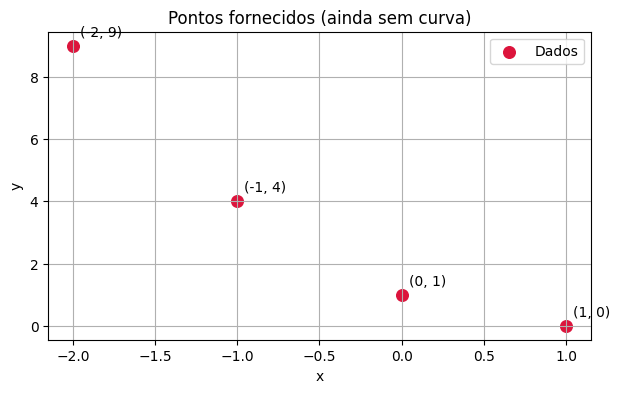

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=70, label="Dados")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi:g}, {yi:g})", (xi, yi), xytext=(5, 7), textcoords="offset points")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Pontos fornecidos (ainda sem curva)")
plt.grid(True); plt.legend(); plt.show()

#3.

Os pontos fornecidos são: (-2 , 9), (-1 , 4), (0 , 1).

A tendência dos pontosé decrescente com desaceleração conforme x aumenta.

A curva não precisa ser reta, pois uma reta não consegue passar por estes 4 pontos ao mesmo tempo.

Existem infinitas curvas gerais qu e passam por esses pontos, mas existe um único polinômio de grau no máximo 3 que passa exatamente por todos eles.

In [2]:
polinomio = np.polynomial.Polynomial.fit(x, y, deg=len(x)-1).convert()
print("Polinômio na forma usual:")
print(polinomio)
print("\nCoeficientes em ordem crescente (termo constante primeiro):")
print(polinomio.coef)

Polinômio na forma usual:
1.0 - 2.0·x + 1.0·x² + (7.43830132e-16)·x³

Coeficientes em ordem crescente (termo constante primeiro):
[ 1.00000000e+00 -2.00000000e+00  1.00000000e+00  7.43830132e-16]


Expressão obtida: $P(x) = 1.0 - 2.0x + 1.0x^2 + (7.44 \times 10^{-16})x^3$

Grau efetivo: O coeficiente de $x^3$ é da ordem de $10^{-16}$. Portanto, o grau real do polinômio é 2 (Quadrático).

Forma simplificada: $P(x) = x^2 - 2x + 1 = (x - 1)^2$.

#4.

1. As diferenças encontradas da ordem de $10^{-15}$ são praticamente zero, representanso apenas erros residuais de arredondamento da máquina.

2. Mostra que o método numérico funcionou corretamente e que o polinômio calculado passa exatamente por todos os pontos fornecidos.

3. Não garante que a curva reflita a realidade física do fenômeno nos pontos intermediários e não garante nada fora do intervalo, onde o polinômio pode crescer ou decrescer rapidamente para o infinito.



In [ ]:
xx = np.linspace(x.min()-0.5, x.max()+0.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, polinomio(xx), label="Polinômio interpolador")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós fornecidos")
plt.axvspan(x.min(), x.max(), color="green", alpha=0.07, label="Intervalo dos dados")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("Curva interpoladora e pontos")
plt.grid(True); plt.legend(); plt.show()

#5.

Sim, a curva passa exatamente por cima de todos os nós vermelhos.

Não, o comportamento que está fora do intervalo não é totalmente sustentado pelos dados. Para x > 1, a parabola volta a crescer. Sem conhecimento do fenômeno real, não podemos afirmar se o sistema realmente voltaria a subir ou se continuaria caindo.

In [ ]:
consultas = np.array([-1.5, -0.5, 0.5, 0.9, 2.0])
for q in consultas:
    tipo = "interpolação" if x.min() <= q <= x.max() else "extrapolação"
    print(f"P({q:4.1f}) = {polinomio(q): .6f}  ({tipo})")

Imagem feita pelo Geogebra

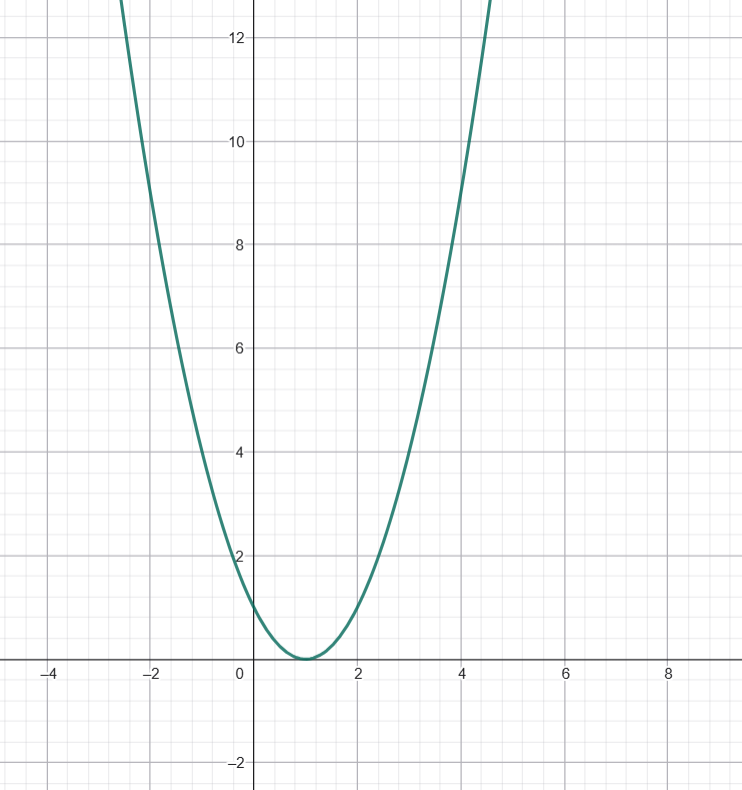

Imagem feita pelo WolframAlpha

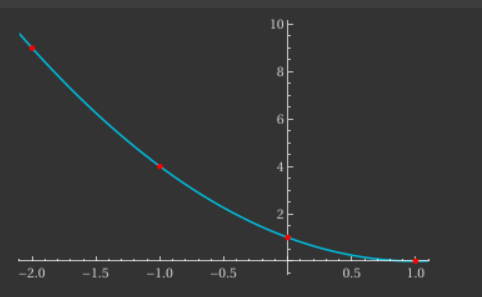

#6.

Tabela

| $x$ consultado | Estimativa $P(x)$ | Interpolação ou extrapolação? |
| :---: | :---: | :---: |
| $-1.5$ | $6.250000$ | Interpolação |
| $-0.5$ | $2.250000$ | Interpolação |
| $0.5$ | $0.250000$ | Interpolação |
| $0.9$ | $0.010000$ | Interpolação |
| $2.0$ | $1.000000$ | Extrapolação |


In [ ]:
xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 2.7, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, deg=len(xB)-1).convert()
print(pB)
print(f"Estimativa em x=1.5: {pB(1.5):.6f}")
xb_plot = np.linspace(xB.min(), xB.max(), 300)
plt.figure(figsize=(7,4)); plt.plot(xb_plot,pB(xb_plot),label="Interpolante")
plt.scatter(xB,yB,color="crimson",label="Medições",zorder=3)
plt.xlabel("Tempo x"); plt.ylabel("Medida y"); plt.grid(True); plt.legend(); plt.show()

#7.

Os nós de tempo são x $x \in \{0, 1, 2, 3\}$. Portanto, $x = 1.5$ está entre os nós, o que é uma interpolação.

A expressão do polinômio de grau 3 obtida é $P(x) = 0.133333x^3 - 0.45x^2 + 1.116667x + 1.2$.

A estimativa pontual interpolada para $x = 1.5$ é $P(1.5) = 2.312500$.

In [ ]:
yB_alterado = yB.copy()
yB_alterado[2] += 0.5
pB_alterado = np.polynomial.Polynomial.fit(xB, yB_alterado, deg=len(xB)-1).convert()
print("Estimativa original em x=1.5:", pB(1.5))
print("Estimativa alterada em x=1.5:", pB_alterado(1.5))
plt.figure(figsize=(8,4))
plt.plot(xb_plot,pB(xb_plot),label="Original")
plt.plot(xb_plot,pB_alterado(xb_plot),"--",label="Com y(2) aumentado em 0.5")
plt.scatter(xB,yB,color="crimson",zorder=3,label="Dados originais")
plt.scatter(xB,yB_alterado,marker="x",s=80,color="black",zorder=4,label="Dados alterados")
plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Efeito de alterar um dado"); plt.show()

#8.

O ponto alterado foi o nó x = 2, cujo valor de y passou de 2.7 para 3.2;

Em x = 1.5, o valo estimado subiu de 2.3125 para 2.59375;

No seu comportamento global, a curva mudou ao longo de todo o intervalo, e não apenas perto de x = 2.

Em relação as incertezas, temo que como a interpolação polinomial global força a curva a passar exatamente por todos os pontos, um erro ou ruído em uma única medição afeta globalmente o formato de toda a curva interpoladora.

In [ ]:
def f(t):
    return 1/(1+25*t**2)

t_plot = np.linspace(-1,1,1000)
plt.figure(figsize=(9,5))
plt.plot(t_plot,f(t_plot),color="black",linewidth=2,label="Função de referência")
for n in [5, 9, 15]:
    tn=np.linspace(-1,1,n)
    pn=np.polynomial.Polynomial.fit(tn,f(tn),deg=n-1).convert()
    plt.plot(t_plot,pn(t_plot),label=f"Interpolante com {n} nós")
    plt.scatter(tn,f(tn),s=18)
plt.ylim(-0.5,1.2); plt.grid(True); plt.legend(); plt.title("Comparação: interpolação polinomial em nós igualmente espaçados")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

#9.

1.Sim. Independentemente do número de nós ($n = 5, 9$ ou $15$), todas as curvas desenhadas passam obrigatoriamente por cima de cada um dos seus respetivos pontos marcados (nós).

2.Perto das extremidades do intervalo (próximo de $x = -1$ e $x = 1$), a curva começa a oscilar intensamente para cima e para baixo. Conforme o número de nós aumenta (especialmente para $n = 15$), essas oscilações nas bordas tornam-se "selvagens" e muito grandes, afastando-se drasticamente da função de referência real. Esse comportamento é o Fenômeno de Runge.

3. Em vez de usar um único polinômio de grau muito elevado para todos os dados, as melhores alternativas são utilizar interpolação por partes (Splines Cúbicas) que conecta os pontos dividindo o intervalo em pequenos trechos e ajustando polinômios de baixo grau (geralmente grau 3) em cada pedaço, garantindo suavidade sem criar oscilações nas bordas. Ou regressão / ajuste por mínimos Quadrados, no qual se os dados tiverem ruído, ajusta-se um modelo de grau menor que siga a tendência geral sem a obrigação de passar exatamente por todos os pontos.

#10.

A curva interpoladora passa por todos os pontos porque o método matemático é construído forçadamente para coincidir com cada nó, independentemente de os dados serem corretos ou não. A interpolação assume que todos os pontos são perfeitamente exatos e ajusta a função para satisfazer essa condição. Portanto, se houver ruído ou erro de medição nos dados do conjunto B, a curva vai simplesmente absorver esse erro e distorcer o seu formato para conseguir tocar o ponto incorreto, sem indicar se o dado original era confiável.


#11.

Interpolar significa estimar valores intermediários dentro do intervalo de dados conhecidos, enquanto extrapolar é estimar valores fora desse domínio, assumindo maior risco de erro. Na aula, testamos a ferramenta Python (via Colab) e o GeoGebra/WolframAlpha, observando que todas concordaram exatamente nos resultados do polinômio de grau 2 ($x^2 - 2x + 1$). Quando alteramos um único dado no experimento, a curva interpoladora mudou a sua forma de maneira global ao longo de todo o intervalo, mostrando que o método é muito sensível a ruídos. Uma limitação importante da interpolação polinomial de grau elevado é a ocorrência de oscilações indesejadas (Fenômeno de Runge). Em uma situação prática, usaríamos a interpolação para estimar dados intermediários contínuos (como temperatura ao longo do tempo), mantendo a cautela de não usar polinômios de grau muito alto e evitando fazer extrapolações distantes dos nós conhecidos.